# Step 4: advanced models
**BT4222 Group 5 · Impression-Aware Re-ranking of Search Results on JD.com**

Trains the re-rankers that go beyond the step-3 baselines and decides, on validation users only, which feature groups and which history design to keep. Test users are scored once, in section 7.

Two models, both scored by the shared `jd_eval.py` that step 3 writes, so every number lands in one table with step 3:

1. **LightGBM LambdaRank** on the frozen step-2 model set (`model_features.json`, 35 features in 8 hypothesis groups). Section 4 removes one group at a time and keeps a group only if removing it lowers validation NDCG@10 by more than chance.
2. **Short/long-term attention ranker** (section 5). Step 1 found the history is three logs kept for different periods: clicks 7 days, carts 90, orders 365. So the model reads the history as two streams: the last week of clicks (what the user wants now) and the carts and orders (lasting preferences). Each stream is attended to from the candidate's point of view. Items are represented by their shop, brand and finest category, never by item id, because more than half of the candidates (56.5% in step 3) appear in no user's history and an item-id embedding would learn nothing for them. Section 5 also trains the same model with one pooled stream and with no history at all, to test whether the split matters.

Section 6 blends the two rankers, with the weight chosen on validation. Section 7.1 separates how much of LightGBM's gain over the step-3 bar comes from the training settings and how much from the features.

| | |
|---|---|
| **Inputs** | `processed/artifacts/features/features_*.parquet`, `model_features.json`, `history_windows.json`, `split_users.parquet` (step 2); `processed/parquet/user_behavior_*.parquet`, `product_meta_*.parquet` (step 1); `processed/artifacts/jd_eval.py` (shared evaluation), `processed/results/step3_results.csv` and `processed/results/per_slate/step3_*.parquet` (written by step 3, so run step 3 first) |
| **Outputs** | `processed/artifacts/step4/` (ablation results, final LightGBM model, attention checkpoints, scores per impression), `processed/results/step4_results.csv` (one row per model and split, in step 3's format), `step4_test_table.csv` (step 3 and step 4 test rows together), `step4_paired_differences.csv`, per-slate test frames `processed/results/per_slate/step4_*.parquet`, figures in `processed/results/figures/` |
| **Runtime** | GPU runtime (T4). The saved run took about 22 minutes, with the ablation fits, the final LightGBM and the attention models loaded from earlier saves; section 7.1's control LightGBM alone took 14 minutes (838 s). A run from scratch (`CFG["rerun"] = True`) takes longer, and each expensive step prints its time. Every expensive step saves its result, so after a disconnect, Run all resumes where it stopped |
| **Next** | `step5_diagnostics.ipynb` reads the saved test scores and the final LightGBM |

**How to run.** Runtime → Change runtime type → T4 GPU. Then Runtime → Run all. Save with outputs (File → Save) before committing to GitHub.

## 0. Setup

In [2]:
import os, sys, gc, glob, json, time, hashlib, subprocess
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import pyarrow.compute as pc
import matplotlib.pyplot as plt
from IPython.display import display, HTML

try:
    import lightgbm as lgb
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm"], check=True)
    import lightgbm as lgb
import torch
import torch.nn as nn
import torch.nn.functional as F

try:                                   # Colab: mount Drive. Elsewhere: set JD_BASE instead
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

BASE = os.environ.get("JD_BASE", "/content/drive/MyDrive/JDsearch_rawData")
assert os.path.isdir(BASE), f"{BASE} not found: add a shortcut to JDsearch_rawData in My Drive"
PROC = os.path.join(BASE, "processed")
PATHS = {"parquet": os.path.join(PROC, "parquet"), "artifacts": os.path.join(PROC, "artifacts"),
         "features": os.path.join(PROC, "artifacts", "features"), "step4": os.path.join(PROC, "artifacts", "step4"),
         "results": os.path.join(PROC, "results"), "figures": os.path.join(PROC, "results", "figures"),
         "per_slate": os.path.join(PROC, "results", "per_slate")}
for key in ("step4", "results", "figures", "per_slate"):
    os.makedirs(PATHS[key], exist_ok=True)

STEP3_RESULTS = os.path.join(PATHS["results"], "step3_results.csv")
for f in (os.path.join(PATHS["artifacts"], "jd_eval.py"), STEP3_RESULTS,
          *(os.path.join(PATHS["per_slate"], f"step3_{m}__score.parquet") for m in ("interim16_lgb", "pop_other"))):
    assert os.path.exists(f), f"{f} not found: run step 3 first"

sys.path.insert(0, PATHS["artifacts"])
sys.modules.pop("jd_eval", None)
import jd_eval as J
assert hasattr(J, "summarize"), f"{J.__file__} is not the step-3 evaluation module: run step 3 first"
print("evaluation module:", J.__file__)

SMOKE = os.environ.get("JD_SMOKE") == "1"      # tiny settings for a local test run; leave unset on Colab
CFG = {
    "seed": 42,
    "rerun": False,                 # True: ignore saved step-4 results and recompute everything
    "ablation_users": 400 if SMOKE else 30_000,     # training users per ablation fit
    "lgb_rounds_ablation": 60 if SMOKE else 600,
    "lgb_rounds_final": 80 if SMOKE else 1000,
    "early_stop": 20 if SMOKE else 50,
    "train_eval_users": 300 if SMOKE else 20_000,   # training users scored to report training performance
    "attn": {"short_len": 64, "long_len": 128, "d_attr": 32, "d": 64, "heads": 2, "batch": 64 if SMOKE else 128,
             "epochs": 2 if SMOKE else 3, "lr": 1e-3, "weight_decay": 1e-5, "min_count": 2 if SMOKE else 5},
    "blend_grid": [round(w, 1) for w in np.arange(0, 1.01, 0.1)],
}
SEED = CFG["seed"]
N_BOOT = 100 if SMOKE else 1000
LGB_PARAMS = {"objective": "lambdarank", "metric": "ndcg", "eval_at": [10], "label_gain": [0, 1, 3, 7],
              "learning_rate": 0.05, "num_leaves": 63, "min_data_in_leaf": 100, "feature_fraction": 0.9,
              "lambdarank_truncation_level": 20, "num_threads": os.cpu_count(), "seed": CFG["seed"], "verbose": -1}

MF = json.load(open(os.path.join(PATHS["artifacts"], "model_features.json")))
GROUPS, MODEL = MF["groups"], MF["model_features"]
POP_VARIANT = MF["exploratory_variants"]["+ pooled popularity"]["add"]
WIN = json.load(open(os.path.join(PATHS["artifacts"], "history_windows.json")))["windows_days"]
W_CLICK, W_CART, W_ORD = float(WIN["CLICK"]), float(WIN["CART"]), float(WIN["ORD"])
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
rng = np.random.default_rng(CFG["seed"])
torch.manual_seed(CFG["seed"])
print(f"model set v{MF['version']}: {len(MODEL)} features in {len(GROUPS)} groups | windows {WIN} | device {DEVICE}"
      + (" | SMOKE TEST SETTINGS" if SMOKE else ""))

def done(name):
    """A saved step-4 result exists and CFG['rerun'] is off, so the cell can load instead of recompute."""
    return (not CFG["rerun"]) and os.path.exists(os.path.join(PATHS["step4"], name))

def show_result(title, obj=None, note=""):
    """Red RESULT banner, then the table, so key outputs stand out in the saved notebook."""
    extra = f'<div style="font-size:90%;margin-top:3px">{note}</div>' if note else ""
    display(HTML('<div style="border-left:6px solid #c0392b;background:#fbeaea;color:#1f1f1f;'
                 'padding:8px 12px;margin:12px 0 4px 0;font-family:Arial,sans-serif">'
                 f"<b>RESULT</b> &nbsp;|&nbsp; {title}{extra}</div>"))
    if obj is not None:
        display(obj)


Mounted at /content/drive
evaluation module: /content/drive/MyDrive/JDsearch_rawData/processed/artifacts/jd_eval.py
model set v1.0: 35 features in 8 groups | windows {'CLICK': 7, 'CART': 90, 'ORD': 365, 'FLW': 89} | device cuda


## 1. Load the impression table
One row per (user, candidate), in the shuffled step-1 order, so tied scores never favour the raw file's positives-first order. Rows of a user are contiguous, which LightGBM needs for its query groups.

In [3]:
FEATS = list(dict.fromkeys(MODEL + POP_VARIANT))
COL = {f: i for i, f in enumerate(FEATS)}
fparts = sorted(glob.glob(os.path.join(PATHS["features"], "features_*.parquet")))
assert fparts and not [f for f in fparts if " (" in os.path.basename(f)], "features missing or Drive duplicate copies present"
n_rows = sum(pq.ParquetFile(f).metadata.num_rows for f in fparts)
X = np.empty((n_rows, len(FEATS)), dtype=np.float32)
USER = np.empty(n_rows, np.int32); WID = np.empty(n_rows, np.int64); LABEL = np.empty(n_rows, np.int8)
SPLIT = np.empty(n_rows, np.int8)
SPLIT_CODE = {"train": 0, "val": 1, "test": 2}
pos = 0
for f in fparts:
    t = pq.read_table(f, columns=["user_id", "wid", "label", "split"] + FEATS)
    n = t.num_rows
    USER[pos:pos + n] = t["user_id"].to_numpy(); WID[pos:pos + n] = t["wid"].to_numpy()
    LABEL[pos:pos + n] = t["label"].to_numpy()
    SPLIT[pos:pos + n] = pd.Series(t["split"].to_numpy()).map(SPLIT_CODE).to_numpy()
    for c in FEATS:
        X[pos:pos + n, COL[c]] = t[c].to_numpy()
    pos += n
    del t
assert (np.diff(USER) >= 0).all(), "rows are not grouped by user"
starts = np.r_[0, np.flatnonzero(np.diff(USER)) + 1]
SLATE_USER, SLATE_START, SLATE_LEN = USER[starts], starts, np.diff(np.r_[starts, n_rows])
SLATE_SPLIT = SPLIT[starts]
SLATE_HAS_POS = np.maximum.reduceat(LABEL, starts) > 0

COLD = X[:, COL["i_pop_any"]] == 0
summary = pd.DataFrame({s: {"users": int((SLATE_SPLIT == c).sum()), "impressions": int((SPLIT == c).sum()),
                            "slates with a positive": int(((SLATE_SPLIT == c) & SLATE_HAS_POS).sum()),
                            "cold impressions": f"{COLD[SPLIT == c].mean():.1%}"}
                        for s, c in SPLIT_CODE.items()}).T
display(summary)
print(f"{n_rows:,} impressions x {len(FEATS)} features ({X.nbytes / 1e9:.1f} GB) | cold = item in no user's history (i_pop_any == 0), as in step 3")

def rows_of(split_code, users=None):
    """Row indices of a split, optionally only some of its users."""
    m = SPLIT == split_code
    if users is not None:
        m &= np.isin(USER, users)
    return np.flatnonzero(m)

LABELS = {"lgbm_kept": "LightGBM LambdaRank (kept groups)", "attn_split": "Attention ranker (split streams)",
          "attn_pooled": "Attention ranker (pooled stream)", "attn_none": "Attention ranker (no history)"}
ROWS4 = []

def score_rows(key, label, rows, score, split, note="", save=False):
    """Evaluate one model on the given rows in step 3's format. Returns the per-slate frame and the results row."""
    df = J.evaluate(USER[rows], LABEL[rows], score, COLD[rows], seed=SEED)
    row = {"model": key, "label": label, "family": "advanced model", "scoring": "score", "protocol": "full slates",
           "split": split, "users": len(np.unique(USER[rows])), "note": note, **J.summarize(df, n_boot=N_BOOT, seed=SEED)}
    ROWS4.append(row)
    if save:
        df.to_parquet(os.path.join(PATHS["per_slate"], f"step4_{key}__score.parquet"), index=False)
    return df, row

VAL = rows_of(1)
TEST = rows_of(2)

,users,impressions,slates with a positive,cold impressions
train,139075,12416335,137397,56.5%
val,17251,1526653,17034,56.9%
test,17505,1567024,17297,56.5%


15,510,012 impressions x 36 features (2.2 GB) | cold = item in no user's history (i_pop_any == 0), as in step 3


## 3. LightGBM helpers
LambdaRank with graded gains 0, 1, 3, 7 (the same 2^label − 1 as `jd_eval`). Training uses only slates with at least one positive: a slate with no positive gives LambdaRank no pairs to learn from. Early stopping watches validation NDCG@10 on validation slates with a positive. Missing values stay missing: LightGBM learns which side of each split they go, so "no match" is kept distinct from "match long ago".

In [4]:
def slate_rows(slate_mask):
    """Row indices of the chosen slates, kept contiguous per slate."""
    s, l = SLATE_START[slate_mask], SLATE_LEN[slate_mask]
    return np.repeat(s, l) + (np.arange(l.sum()) - np.repeat(np.cumsum(l) - l, l)), l

def lgb_data(slate_mask, cols, reference=None, data=None):
    mat, col = data or (X, COL)
    rows, groups = slate_rows(slate_mask)
    ds = lgb.Dataset(mat[np.ix_(rows, [col[c] for c in cols])], label=LABEL[rows], group=groups,
                     feature_name=cols, free_raw_data=True, reference=reference)
    return ds, rows

def fit_lgb(cols, train_slates, rounds, data=None):
    dtrain, _ = lgb_data(train_slates, cols, data=data)
    dval, _ = lgb_data((SLATE_SPLIT == 1) & SLATE_HAS_POS, cols, reference=dtrain, data=data)
    booster = lgb.train(LGB_PARAMS, dtrain, num_boost_round=rounds, valid_sets=[dval], valid_names=["val"],
                        callbacks=[lgb.early_stopping(CFG["early_stop"], verbose=False)])
    return booster

def predict(booster, rows, cols, chunk=2_000_000, data=None):
    mat, col = data or (X, COL)
    out = np.empty(len(rows), np.float32)
    for i in range(0, len(rows), chunk):
        r = rows[i:i + chunk]
        out[i:i + chunk] = booster.predict(mat[np.ix_(r, [col[c] for c in cols])], num_iteration=booster.best_iteration)
    return out

## 4. Which feature groups earn their place
Every fit uses the same sample of training users and the same settings, and differs only in its feature columns. For each group, the model without it is compared with the full model on the same validation slates. The difference in NDCG@10 per slate gives a mean and a 95% interval. **A group stays only if removing it lowers NDCG@10 and the interval excludes zero**, the rule step 2 committed to before any model was trained.

The exploratory variant from step 2, adding pooled popularity, is fitted on the same sample and reported separately, because it was chosen after looking at results.

In [5]:
train_users = SLATE_USER[(SLATE_SPLIT == 0) & SLATE_HAS_POS]
abl_users = np.sort(rng.choice(train_users, min(CFG["ablation_users"], len(train_users)), replace=False))
ABL_SLATES = np.isin(SLATE_USER, abl_users)
CONFIGS = {"all groups": MODEL}
CONFIGS.update({f"without {g}": [f for f in MODEL if f not in feats] for g, feats in GROUPS.items()})
CONFIGS["all groups + pooled popularity (exploratory)"] = MODEL + POP_VARIANT

val_slates = {}
for name, cols in CONFIGS.items():
    key = json.dumps([cols, CFG["ablation_users"], CFG["lgb_rounds_ablation"], LGB_PARAMS["seed"]])
    cache = f"ablation_{hashlib.md5(key.encode()).hexdigest()[:10]}.npy"
    path = os.path.join(PATHS["step4"], cache)
    if done(cache):
        s = np.load(path)
    else:
        t0 = time.time()
        b = fit_lgb(cols, ABL_SLATES, CFG["lgb_rounds_ablation"])
        s = predict(b, VAL, cols)
        np.save(path, s)
        print(f"{name:<55} {b.best_iteration:>4} rounds  {time.time() - t0:,.0f}s")
    val_slates[name] = J.per_slate(USER[VAL], LABEL[VAL], s, seed=SEED)

full = val_slates["all groups"]
abl = []
for name in CONFIGS:
    d = J.paired(full, val_slates[name], "ndcg@10", n_boot=N_BOOT, seed=SEED) if name != "all groups" else {"diff": 0, "lo": 0, "hi": 0}
    abl.append({"configuration": name, "features": len(CONFIGS[name]),
                "val NDCG@10": np.nanmean(val_slates[name]["ndcg@10"]),
                "full minus this": d["diff"], "95% low": d["lo"], "95% high": d["hi"]})
abl = pd.DataFrame(abl).set_index("configuration")
group_rows = [f"without {g}" for g in GROUPS]
abl["keep group"] = ""
abl.loc[group_rows, "keep group"] = np.where(abl.loc[group_rows, "95% low"] > 0, "keep", "drop")
abl.to_csv(os.path.join(PATHS["results"], "step4_ablation.csv"))
show_result("Feature-group ablation on validation users: keep a group when removing it lowers NDCG@10 with an interval above zero", abl.style.format({"val NDCG@10": "{:.4f}", "full minus this": "{:+.4f}", "95% low": "{:+.4f}", "95% high": "{:+.4f}"}))

KEPT = [g for g in GROUPS if abl.loc[f"without {g}", "keep group"] == "keep"]
if not KEPT:
    KEPT = list(GROUPS)
    print("No group passed on its own, so the final model keeps the full frozen set.")
FINAL_COLS = [f for g in KEPT for f in GROUPS[g]]
pop_gain = abl.loc["all groups + pooled popularity (exploratory)", "full minus this"]
print(f"kept {len(KEPT)} of {len(GROUPS)} groups ({len(FINAL_COLS)} features): {KEPT}")
print(f"exploratory pooled popularity changes validation NDCG@10 by {-pop_gain:+.4f} (reported, not used)")

,features,val NDCG@10,full minus this,95% low,95% high,keep group
configuration,,,,,,
all groups,35,0.4241,+0.0000,+0.0000,+0.0000,
without H1 activity inside its window,28,0.4238,+0.0002,-0.0012,+0.0016,drop
without H2 where a match comes from,26,0.4214,+0.0026,+0.0013,+0.0040,keep
without H3 the item itself,31,0.4223,+0.0018,+0.0005,+0.0031,keep
without H4 query as a key into history,32,0.4239,+0.0001,-0.0012,+0.0015,drop
without H5 popularity by type,31,0.4203,+0.0037,+0.0022,+0.0052,keep
without H6 item conversion rate,32,0.4171,+0.0070,+0.0050,+0.0088,keep
without H7 standing within the slate,32,0.4156,+0.0085,+0.0064,+0.0106,keep
without H8 name overlap by source,33,0.4218,+0.0023,+0.0008,+0.0038,keep


kept 6 of 8 groups (25 features): ['H2 where a match comes from', 'H3 the item itself', 'H5 popularity by type', 'H6 item conversion rate', 'H7 standing within the slate', 'H8 name overlap by source']
exploratory pooled popularity changes validation NDCG@10 by -0.0007 (reported, not used)


### 4.1 Final LightGBM
Kept groups only, every training slate with a positive, early stopping on validation. The model is saved, so a re-run loads it.

,model,label,family,scoring,protocol,split,users,note,ndcg@5,ndcg@5_lo,...,purchase_recall@10_hi,purchase_recall@10_slates,ndcg@10_cold,ndcg@10_cold_lo,ndcg@10_cold_hi,ndcg@10_cold_slates,ndcg@10_warm,ndcg@10_warm_lo,ndcg@10_warm_hi,ndcg@10_warm_slates
0,lgbm_kept,LightGBM LambdaRank (kept groups),advanced model,score,full slates,val,17251,,0.3778,0.372,...,0.7135,1982,0.2488,0.24,0.2576,4949,0.5078,0.5026,0.5137,14311


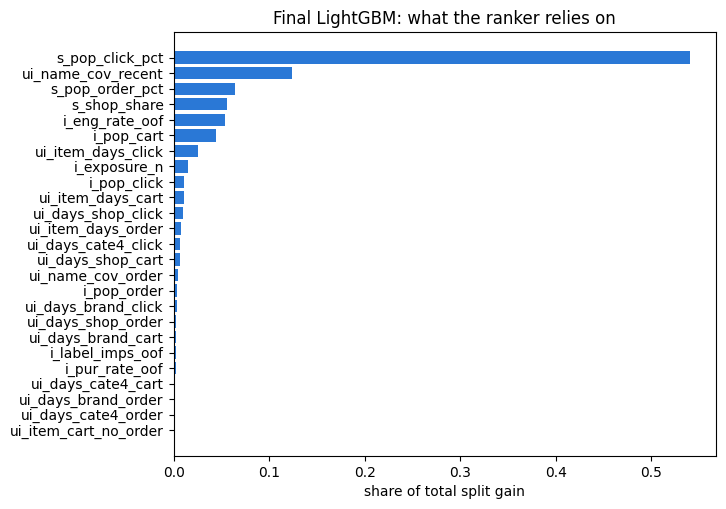

In [6]:
path = os.path.join(PATHS["step4"], "lgbm_final.txt")
if done("lgbm_final.txt"):
    LGBM = lgb.Booster(model_file=path)
    LGBM.best_iteration = int(json.load(open(path + ".json"))["best_iteration"])
else:
    t0 = time.time()
    LGBM = fit_lgb(FINAL_COLS, (SLATE_SPLIT == 0) & SLATE_HAS_POS, CFG["lgb_rounds_final"])
    LGBM.save_model(path, num_iteration=LGBM.best_iteration)
    json.dump({"best_iteration": LGBM.best_iteration, "features": FINAL_COLS, "kept_groups": KEPT}, open(path + ".json", "w"))
    print(f"final LightGBM: {LGBM.best_iteration} rounds, {time.time() - t0:,.0f}s")
LGBM_FEATS = LGBM.feature_name()
S_LGB_VAL = predict(LGBM, VAL, LGBM_FEATS)
_, lgb_val = score_rows("lgbm_kept", LABELS["lgbm_kept"], VAL, S_LGB_VAL, "val")
show_result("Final LightGBM on the kept groups, validation users", pd.DataFrame([lgb_val]).round(4))

imp = pd.Series(LGBM.feature_importance("gain"), index=LGBM_FEATS).sort_values()
imp = imp / imp.sum()
fig, ax = plt.subplots(figsize=(7, max(3, 0.22 * len(imp))))
ax.barh(imp.index, imp.values, color="#2a78d6")
ax.set_xlabel("share of total split gain"); ax.set_title("Final LightGBM: what the ranker relies on")
fig.savefig(os.path.join(PATHS["figures"], "step4_lgbm_importance.png"), dpi=200, bbox_inches="tight")
plt.show()

## 5. Short/long-term attention ranker
**Inputs per candidate.** Its shop, brand and finest category, each embedded and combined into one item vector, plus the 35 model features from step 2 (counts log-scaled, "days since" turned into 1 / (1 + days), a flag for every value that can be missing, then standardised on training rows).

**History.** Each past event is the same item vector plus an embedding of its type and of how old it is (10 age buckets from under a day to a year). The *short* stream holds the last 64 clicks inside the click window, the *long* stream the last 128 carts and orders inside their windows.

**Attention.** The candidate's item vector asks each stream which past events resemble it (2-head dot-product attention). A learned "nothing here" slot is always present, so a user with an empty stream still gets an answer. The candidate vector, the feature vector, and each stream's answer (and its product with the candidate) feed a small network that outputs the score.

**Training.** Listwise: for each slate, a softmax over its candidates is pushed towards the slate's gains (2^label − 1), which optimises the same ordering NDCG rewards. Slates with no positive are skipped. The epoch with the best validation NDCG@10 is kept.

**Three variants**, identical except for the history: `split` (two streams), `pooled` (one stream holding all events, as the interim's pooled features did), and `none` (no history). Comparing them on validation tests whether keeping clicks apart from carts and orders matters.

In [7]:
# 5.1 Product attributes and vocabularies (ids seen fewer than min_count times in training data share one "rare" slot)
t = pa.concat_tables([pq.read_table(f, columns=["wid", "shop_id", "brand_id", "cate_id_4"])
                      for f in sorted(glob.glob(os.path.join(PATHS["parquet"], "product_meta_*.parquet")))])
order = np.argsort(t["wid"].to_numpy(), kind="stable")
META_WID = t["wid"].to_numpy()[order]
META_ATTR = np.stack([t[c].to_numpy()[order] for c in ("shop_id", "brand_id", "cate_id_4")], 1).astype(np.int64)
del t, order

def attrs_of(wids):
    p = np.clip(np.searchsorted(META_WID, wids), 0, len(META_WID) - 1)
    hit = META_WID[p] == wids
    return np.where(hit[:, None], META_ATTR[p], -1)

hparts = sorted(glob.glob(os.path.join(PATHS["parquet"], "user_behavior_*.parquet")))
h_user, h_wid, h_type, h_age = [], [], [], []
for f in hparts:
    t = pq.read_table(f, columns=["user_id", "history_wids", "history_types", "history_age_days"])
    n = pc.list_value_length(t["history_wids"]).to_numpy()
    h_user.append(np.repeat(t["user_id"].to_numpy(), n).astype(np.int32))
    h_wid.append(pc.list_flatten(t["history_wids"]).to_numpy())
    h_type.append(pc.list_flatten(t["history_types"]).to_numpy().astype(np.int8))
    h_age.append(pc.list_flatten(t["history_age_days"]).to_numpy().astype(np.float32))
    del t
h_user, h_wid, h_type, h_age = map(np.concatenate, (h_user, h_wid, h_type, h_age))
H_ATTR = attrs_of(h_wid)
C_ATTR = attrs_of(WID)
N_USERS = int(max(USER.max(), h_user.max())) + 1
train_user_mask = np.zeros(N_USERS, bool); train_user_mask[SLATE_USER[SLATE_SPLIT == 0]] = True

VOCAB = []
for k in range(3):
    v = np.concatenate([H_ATTR[train_user_mask[h_user], k], C_ATTR[SPLIT == 0, k]])
    u, c = np.unique(v[v >= 0], return_counts=True)
    VOCAB.append(u[c >= CFG["attn"]["min_count"]])

def encode(a):
    """Raw attribute ids -> embedding rows: 0 padding, 1 missing or rare, 2+ known ids."""
    out = np.ones(a.shape, np.int32)
    for k in range(3):
        if len(VOCAB[k]):
            p = np.clip(np.searchsorted(VOCAB[k], a[:, k]), 0, len(VOCAB[k]) - 1)
            out[:, k] = np.where(VOCAB[k][p] == a[:, k], p + 2, 1)
    return out

C_IDS = encode(C_ATTR)
H_IDS = encode(H_ATTR)
print("vocabulary sizes (shop, brand, category):", [len(v) + 2 for v in VOCAB],
      f"| candidates with a known shop: {(C_IDS[:, 0] > 1).mean():.1%}")

vocabulary sizes (shop, brand, category): [203538, 125805, 6356] | candidates with a known shop: 98.0%


In [8]:
# 5.2 History streams as fixed-size arrays per user: [shop, brand, cate, type, age bucket], most recent first
AGE_EDGES = np.array([1, 3, 7, 14, 30, 60, 90, 180, 365], np.float32)
age_bucket = (np.digitize(h_age, AGE_EDGES) + 1).astype(np.int32)     # 1..10; 0 is padding
short_m = (h_type == 1) & (h_age < W_CLICK)
long_m = ((h_type == 2) & (h_age < W_CART)) | ((h_type == 3) & (h_age < W_ORD))

def stream(mask, length):
    arr = np.zeros((N_USERS, length, 5), np.int32)
    idx = np.flatnonzero(mask)[::-1]                    # history is oldest-first, so reversed is newest-first
    u = h_user[idx]
    o = np.lexsort((np.arange(len(idx)), u))
    idx, u = idx[o], u[o]
    first = np.r_[0, np.flatnonzero(np.diff(u)) + 1]
    pos_in_user = np.arange(len(u)) - np.repeat(first, np.diff(np.r_[first, len(u)]))
    keep = pos_in_user < length
    idx, u, p = idx[keep], u[keep], pos_in_user[keep]
    arr[u, p, :3] = H_IDS[idx]
    arr[u, p, 3] = h_type[idx]
    arr[u, p, 4] = age_bucket[idx]
    return arr

SHORT = stream(short_m, CFG["attn"]["short_len"])
LONG = stream(long_m, CFG["attn"]["long_len"])
fill = pd.DataFrame({"short (clicks, last 7 days)": [(SHORT[:, :, 3] > 0).sum(1).mean(), ((SHORT[:, :, 3] > 0).sum(1) == 0).mean()],
                     "long (carts 90 d, orders 365 d)": [(LONG[:, :, 3] > 0).sum(1).mean(), ((LONG[:, :, 3] > 0).sum(1) == 0).mean()]},
                    index=["events per user (mean)", "users with an empty stream"])
display(fill.round(3))
del h_user, h_wid, h_type, h_age, H_ATTR, H_IDS, age_bucket, short_m, long_m
_ = gc.collect()

,"short (clicks, last 7 days)","long (carts 90 d, orders 365 d)"
events per user (mean),26.219,61.921
users with an empty stream,0.162,0.015


In [9]:
# 5.3 Candidate features for the network: log counts, 1/(1+days), missing flags, standardised on training rows
DENSE_SRC = MODEL
log_like = [f for f in DENSE_SRC if f.startswith(("i_pop", "i_exposure", "i_label_imps", "u_n_"))]
days_like = [f for f in DENSE_SRC if "days" in f]
has_nan = [f for f in DENSE_SRC if np.isnan(X[:, COL[f]]).any()]
DENSE = np.empty((n_rows, len(DENSE_SRC) + len(has_nan)), np.float16)
tr_rows = rows_of(0)
for j, f in enumerate(DENSE_SRC + [f"{f} missing" for f in has_nan]):
    if j < len(DENSE_SRC):
        x = X[:, COL[f]].astype(np.float32)
        if f in days_like:
            x = 1.0 / (1.0 + np.maximum(x, 0))
        elif f in log_like:
            x = np.log1p(np.maximum(x, 0))
        x = np.nan_to_num(x, nan=0.0)
    else:
        x = np.isnan(X[:, COL[f.removesuffix(" missing")]]).astype(np.float32)
    mu, sd = x[tr_rows].mean(), x[tr_rows].std() + 1e-6
    DENSE[:, j] = np.clip((x - mu) / sd, -10, 10)
print(f"network input per candidate: 3 attribute ids + {DENSE.shape[1]} features "
      f"({len(DENSE_SRC)} model features, {len(has_nan)} missing flags)")

network input per candidate: 3 attribute ids + 58 features (35 model features, 23 missing flags)


In [10]:
# 5.4 Model and batching
class AttnRanker(nn.Module):
    def __init__(self, vocab_sizes, n_dense, streams, d_attr, d, heads):
        super().__init__()
        self.streams = streams
        self.emb = nn.ModuleList([nn.Embedding(v, d_attr, padding_idx=0) for v in vocab_sizes])
        self.item = nn.Sequential(nn.Linear(3 * d_attr, d), nn.LayerNorm(d))
        self.type_emb = nn.Embedding(5, d, padding_idx=0)
        self.age_emb = nn.Embedding(len(AGE_EDGES) + 2, d, padding_idx=0)
        self.attn = nn.ModuleDict({s: nn.MultiheadAttention(d, heads, batch_first=True) for s in streams})
        self.empty = nn.ParameterDict({s: nn.Parameter(torch.zeros(1, 1, d)) for s in streams})
        self.dense = nn.Sequential(nn.Linear(n_dense, d), nn.ReLU())
        self.head = nn.Sequential(nn.Linear(d * (2 + 2 * len(streams)), 128), nn.ReLU(), nn.Dropout(0.1), nn.Linear(128, 1))

    def items(self, ids):
        return self.item(torch.cat([e(ids[..., k]) for k, e in enumerate(self.emb)], -1))

    def forward(self, cand, dense, seqs, want_weights=False):
        q = self.items(cand)
        parts, weights = [q, self.dense(dense)], {}
        for s in self.streams:
            ev = seqs[s]
            kv = self.items(ev[..., :3]) + self.type_emb(ev[..., 3]) + self.age_emb(ev[..., 4])
            kv = torch.cat([self.empty[s].expand(len(ev), 1, -1), kv], 1)
            pad = torch.cat([torch.zeros(len(ev), 1, dtype=torch.bool, device=ev.device), ev[..., 3] == 0], 1)
            out, w = self.attn[s](q, kv, kv, key_padding_mask=pad, need_weights=want_weights)
            parts += [out, q * out]
            weights[s] = w
        score = self.head(torch.cat(parts, -1)).squeeze(-1)
        return (score, weights) if want_weights else score

STREAMS = {"split": ["short", "long"], "pooled": ["all"], "none": []}

def batch(users, mode):
    """Pad a list of slates to the longest one. Returns tensors on DEVICE and the row index of every cell (-1 = pad)."""
    s, l = SLATE_START[users], SLATE_LEN[users]
    C = int(l.max())
    rows = s[:, None] + np.arange(C)[None, :]
    valid = np.arange(C)[None, :] < l[:, None]
    rows = np.where(valid, rows, -1)
    r = np.where(valid, rows, 0)
    uid = SLATE_USER[users]
    seqs = {}
    if mode == "split":
        seqs = {"short": SHORT[uid], "long": LONG[uid]}
    elif mode == "pooled":
        seqs = {"all": np.concatenate([SHORT[uid], LONG[uid]], 1)}
    to = lambda a, dt: torch.as_tensor(a, dtype=dt, device=DEVICE)
    return (to(C_IDS[r] * valid[..., None], torch.long), to(DENSE[r].astype(np.float32) * valid[..., None], torch.float32),
            {k: to(v, torch.long) for k, v in seqs.items()}, to(LABEL[r] * valid, torch.long), to(valid, torch.bool), rows)

GAIN_T = torch.tensor(2.0 ** np.arange(4) - 1, dtype=torch.float32, device=DEVICE)

def listwise_loss(score, label, valid):
    score = score.float().masked_fill(~valid, -1e4)
    g = GAIN_T[label] * valid
    target = g / g.sum(1, keepdim=True).clamp_min(1e-9)
    return -(target * F.log_softmax(score, 1)).sum(1).mean()

def score_slates(model, slate_idx, mode, bs=256):
    """Scores for every row of the given slates, aligned with the concatenated row order."""
    model.eval()
    rows_all, s_all = [], []
    with torch.no_grad():
        for i in range(0, len(slate_idx), bs):
            cand, dense, seqs, _, valid, rows = batch(slate_idx[i:i + bs], mode)
            with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
                sc = model(cand, dense, seqs).float()
            v = valid.cpu().numpy()
            rows_all.append(rows[v]); s_all.append(sc.cpu().numpy()[v])
    rows_all, s_all = np.concatenate(rows_all), np.concatenate(s_all)
    o = np.argsort(rows_all)
    return rows_all[o], s_all[o]

VAL_SLATES = np.flatnonzero(SLATE_SPLIT == 1)
TEST_SLATES = np.flatnonzero(SLATE_SPLIT == 2)
TRAIN_SLATES = np.flatnonzero((SLATE_SPLIT == 0) & SLATE_HAS_POS)
assert np.array_equal(slate_rows(SLATE_SPLIT == 1)[0], VAL), "validation rows out of order"

def train_attn(mode):
    a = CFG["attn"]
    torch.manual_seed(CFG["seed"])
    model = AttnRanker([len(v) + 2 for v in VOCAB], DENSE.shape[1], STREAMS[mode], a["d_attr"], a["d"], a["heads"]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=a["lr"], weight_decay=a["weight_decay"])
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")
    best, best_state, history = -1, None, []
    r = np.random.default_rng(CFG["seed"])
    for ep in range(a["epochs"]):
        model.train()
        t0, losses = time.time(), []
        for i, b in enumerate(np.array_split(r.permutation(TRAIN_SLATES), max(1, len(TRAIN_SLATES) // a["batch"]))):
            cand, dense, seqs, label, valid, _ = batch(b, mode)
            with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
                loss = listwise_loss(model(cand, dense, seqs), label, valid)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update()
            losses.append(loss.item())
        _, s = score_slates(model, VAL_SLATES, mode)
        ndcg = np.nanmean(J.per_slate(USER[VAL], LABEL[VAL], s, seed=SEED)["ndcg@10"])
        history.append({"epoch": ep + 1, "train loss": np.mean(losses), "val NDCG@10": ndcg, "seconds": time.time() - t0})
        print(f"  {mode:<7} epoch {ep + 1}: loss {np.mean(losses):.4f}  val NDCG@10 {ndcg:.4f}  ({time.time() - t0:,.0f}s)")
        if ndcg > best:
            best, best_state = ndcg, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

In [11]:
# 5.5 Train the three variants (each saved, so a re-run loads it)
ATTN, attn_val = {}, {}
for mode in STREAMS:
    ck = f"attn_{mode}.pt"
    a = CFG["attn"]
    model = AttnRanker([len(v) + 2 for v in VOCAB], DENSE.shape[1], STREAMS[mode], a["d_attr"], a["d"], a["heads"]).to(DEVICE)
    if done(ck):
        model.load_state_dict(torch.load(os.path.join(PATHS["step4"], ck), map_location=DEVICE))
    else:
        model, hist = train_attn(mode)
        torch.save(model.state_dict(), os.path.join(PATHS["step4"], ck))
        hist.to_csv(os.path.join(PATHS["step4"], f"attn_{mode}_history.csv"), index=False)
    ATTN[mode] = model
    _, s = score_slates(model, VAL_SLATES, mode)
    attn_val[mode] = s
    print(f"{mode}: validation scored")

vs, attn_rows = {}, {}
for m in STREAMS:
    vs[m], attn_rows[m] = score_rows(f"attn_{m}", LABELS[f"attn_{m}"], VAL, attn_val[m], "val")
show_result("Attention ranker, three history designs, validation users", pd.DataFrame(attn_rows.values()).round(4))
comp = pd.DataFrame({f"split minus {m}": J.paired(vs["split"], vs[m], "ndcg@10", n_boot=N_BOOT, seed=SEED) for m in ("pooled", "none")}).T
comp_p = pd.DataFrame({f"split minus {m}": J.paired(vs["split"], vs[m], "purchase_recall@10", n_boot=N_BOOT, seed=SEED) for m in ("pooled", "none")}).T
show_result("Split streams against a pooled stream and no history: paired differences on validation slates", pd.concat({"NDCG@10": comp, "purchase Recall@10": comp_p}, axis=1).round(4))

split: validation scored
pooled: validation scored
none: validation scored


,model,label,family,scoring,protocol,split,users,note,ndcg@5,ndcg@5_lo,...,purchase_recall@10_hi,purchase_recall@10_slates,ndcg@10_cold,ndcg@10_cold_lo,ndcg@10_cold_hi,ndcg@10_cold_slates,ndcg@10_warm,ndcg@10_warm_lo,ndcg@10_warm_hi,ndcg@10_warm_slates
0,attn_split,Attention ranker (split streams),advanced model,score,full slates,val,17251,,0.3741,0.3683,...,0.7050,1982,0.2491,0.2404,0.2576,4949,0.5030,0.4977,0.5089,14311
1,attn_pooled,Attention ranker (pooled stream),advanced model,score,full slates,val,17251,,0.3736,0.3677,...,0.7098,1982,0.2492,0.2406,0.2579,4949,0.5028,0.4974,0.5087,14311
2,attn_none,Attention ranker (no history),advanced model,score,full slates,val,17251,,0.3743,0.3683,...,0.7023,1982,0.2468,0.2385,0.2553,4949,0.5029,0.4975,0.5089,14311


NDCG@10                          purchase Recall@10  \
                      diff      lo      hi   slates               diff   
split minus pooled  0.0003 -0.0010  0.0016  17034.0            -0.0047   
split minus none    0.0002 -0.0012  0.0016  17034.0             0.0030   

                                            
                        lo      hi  slates  
split minus pooled -0.0130  0.0035  1982.0  
split minus none   -0.0056  0.0116  1982.0

### 5.6 Where the attention goes
For candidates the user engaged with, in 2,000 validation slates of the split model: how the attention of each stream is spread over event age, and over carts versus orders in the long stream. The "nothing here" slot is shown separately: a high share means the stream had nothing relevant to that candidate.

,short,long
nothing here,0.588,0.130
<1d,0.151,0.046
1-3d,0.142,0.047
3-7d,0.118,0.055
7-14d,0.000,0.055
14-30d,0.000,0.123
30-60d,0.000,0.219
60-90d,0.000,0.130
90-180d,0.000,0.116
180-365d,0.000,0.080


long stream, attention on carts vs orders: 65.5% carts, 34.5% orders


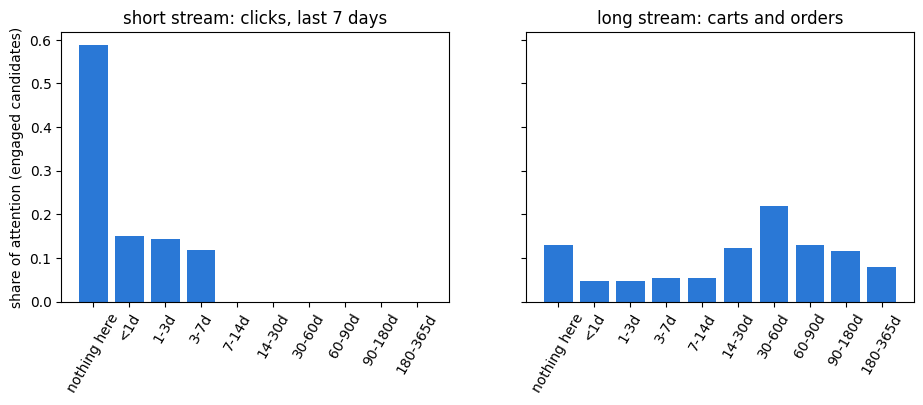

In [12]:
sample = rng.choice(VAL_SLATES[SLATE_HAS_POS[VAL_SLATES]], min(2000, int(SLATE_HAS_POS[VAL_SLATES].sum())), replace=False)
mass = {s: np.zeros(len(AGE_EDGES) + 2) for s in ("short", "long")}
long_type = np.zeros(5)
m = ATTN["split"]; m.eval()
with torch.no_grad():
    for i in range(0, len(sample), 128):
        cand, dense, seqs, label, valid, _ = batch(sample[i:i + 128], "split")
        _, w = m(cand, dense, seqs, want_weights=True)
        pos_mask = (label > 0) & valid
        for s in ("short", "long"):
            ww = w[s][pos_mask].float().cpu().numpy()                  # (positives, 1 + L)
            ab = seqs[s][..., 4].cpu().numpy()                          # (B, L)
            owner = np.nonzero(pos_mask.cpu().numpy())[0]
            mass[s][0] += ww[:, 0].sum()                                # the "nothing here" slot
            np.add.at(mass[s], ab[owner], ww[:, 1:])
            if s == "long":
                np.add.at(long_type, seqs[s][..., 3].cpu().numpy()[owner], ww[:, 1:])
age_names = ["nothing here"] + ["<1d", "1-3d", "3-7d", "7-14d", "14-30d", "30-60d", "60-90d", "90-180d", "180-365d", "365d+"]
att = pd.DataFrame({s: mass[s] / mass[s].sum() for s in mass}, index=age_names)
att = att.drop(index="365d+") if att.loc["365d+"].sum() == 0 else att
show_result("Where the attention goes: share of attention by stream and event age (validation, engaged candidates)", att.round(3))
print(f"long stream, attention on carts vs orders: {long_type[2] / long_type[2:4].sum():.1%} carts, "
      f"{long_type[3] / long_type[2:4].sum():.1%} orders")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, s, title in zip(axes, ("short", "long"), ("short stream: clicks, last 7 days", "long stream: carts and orders")):
    ax.bar(att.index, att[s], color="#2a78d6")
    ax.set_title(title); ax.tick_params(axis="x", rotation=60)
axes[0].set_ylabel("share of attention (engaged candidates)")
fig.savefig(os.path.join(PATHS["figures"], "step4_attention_by_age.png"), dpi=200, bbox_inches="tight")
plt.show()

## 6. Blend the two rankers
Each model's scores are turned into percentiles within the slate, so the two scales are comparable, then mixed as (1 − w) · LightGBM + w · attention. The weight w is chosen on validation.

In [13]:
def slate_pct(rows, score):
    return pd.Series(score).groupby(USER[rows]).rank(pct=True).to_numpy()

p_lgb, p_att = slate_pct(VAL, S_LGB_VAL), slate_pct(VAL, attn_val["split"])
GRID_COLS = ["ndcg@10", "ndcg@5", "purchase_recall@10"]
grid = pd.DataFrame([{"w (attention share)": w, **{m: np.nanmean(df[m]) for m in GRID_COLS}}
                     for w in CFG["blend_grid"]
                     for df in [J.per_slate(USER[VAL], LABEL[VAL], (1 - w) * p_lgb + w * p_att, seed=SEED)]]).set_index("w (attention share)")
W_BLEND = float(grid["ndcg@10"].idxmax())
LABELS["blend"] = f"Blend (w = {W_BLEND})"
_, blend_val = score_rows("blend", LABELS["blend"], VAL, (1 - W_BLEND) * p_lgb + W_BLEND * p_att, "val")
VAL_NDCG = {"lgbm_kept": lgb_val["ndcg@10"], "attn_split": attn_rows["split"]["ndcg@10"], "blend": blend_val["ndcg@10"]}
show_result("Blend weight against validation NDCG@10", grid.round(4))
print(f"chosen blend weight on validation: w = {W_BLEND}")

,ndcg@10,ndcg@5,purchase_recall@10
w (attention share),,,
0.0,0.4268,0.3778,0.6933
0.1,0.4271,0.3781,0.6948
0.2,0.4273,0.3780,0.6953
0.3,0.4273,0.3781,0.6973
0.4,0.4269,0.3780,0.6956
0.5,0.4258,0.3772,0.6950
0.6,0.4253,0.3771,0.6943
0.7,0.4245,0.3760,0.6933
0.8,0.4235,0.3751,0.6903


chosen blend weight on validation: w = 0.2


## 7. Test users, scored once
Everything above was decided on validation. This cell scores the test users for the final models and the training users (the same 20,000-user sample step 3 uses) to show how much each model overfits. The step-4 rows go to `step4_results.csv` in step 3's format, then sit beside the step-3 test rows in one table. Cold and warm items are reported separately: cold = item in no user's history, as in step 3.

In [14]:
split_users = pd.read_parquet(os.path.join(PATHS["artifacts"], "split_users.parquet"))
USERS = {"train": np.sort(split_users.loc[split_users["split"] == "train", "user_id"].to_numpy().astype(np.int64))}
train_eval_users = np.sort(np.random.default_rng(SEED + 1).choice(USERS["train"], min(CFG["train_eval_users"], len(USERS["train"])), replace=False))
TR = rows_of(0, train_eval_users)
TR_SLATES = np.flatnonzero(np.isin(SLATE_USER, train_eval_users))
TEST_DF = {}
for split_name, rows, slates in (("train", TR, TR_SLATES), ("test", TEST, TEST_SLATES)):
    test = split_name == "test"
    s_lgb = predict(LGBM, rows, LGBM_FEATS)
    s_att = {m: score_slates(ATTN[m], slates, m)[1] for m in (STREAMS if test else ["split"])}
    blend = (1 - W_BLEND) * slate_pct(rows, s_lgb) + W_BLEND * slate_pct(rows, s_att["split"])
    scores = {"lgbm_kept": s_lgb, **{f"attn_{m}": s for m, s in s_att.items()}, "blend": blend}
    for key, s in scores.items():
        TEST_DF[key], _ = score_rows(key, LABELS[key], rows, s, split_name, save=test)
    if test:
        pd.DataFrame({"user_id": USER[rows], "wid": WID[rows], "label": LABEL[rows], "cold": COLD[rows],
                      "lightgbm": s_lgb, "attention": s_att["split"], "blend": blend}).to_parquet(
            os.path.join(PATHS["step4"], "test_scores.parquet"), index=False)
RESULTS = pd.DataFrame(ROWS4)
RESULTS.to_csv(os.path.join(PATHS["results"], "step4_results.csv"), index=False)

S3 = pd.read_csv(STEP3_RESULTS)
S3 = S3[(S3["split"] == "test") & (S3["protocol"] == "full slates")]
both = pd.concat([S3, RESULTS[RESULTS["split"] == "test"]], ignore_index=True)
ci = lambda m: both.apply(lambda r: f"{r[m]:.4f} [{r[m + '_lo']:.4f}, {r[m + '_hi']:.4f}]", axis=1)
table = pd.DataFrame({"model": both["model"], "label": both["label"], "scoring": both["scoring"],
                      "NDCG@10 [95% CI]": ci("ndcg@10"), "purchase Recall@10 [95% CI]": ci("purchase_recall@10"),
                      "ndcg@5": both["ndcg@5"], "hr@10": both["hr@10"],
                      "ndcg@10_cold": both["ndcg@10_cold"], "ndcg@10_warm": both["ndcg@10_warm"]})
table.to_csv(os.path.join(PATHS["results"], "step4_test_table.csv"), index=False)
show_result("Test performance, full slates: step-3 and step-4 models", table.round(4))
show_result("NDCG@10 on the training sample, validation and test", RESULTS.pivot_table(index="model", columns="split", values="ndcg@10", sort=False).round(4))

,model,label,scoring,NDCG@10 [95% CI],purchase Recall@10 [95% CI],ndcg@5,hr@10,ndcg@10_cold,ndcg@10_warm
0,random,Random,score,"0.0800 [0.0771, 0.0828]","0.1263 [0.1129, 0.1402]",0.0562,0.2193,0.1231,0.1898
1,pop_other,Popularity (other users),score,"0.3423 [0.3372, 0.3477]","0.5979 [0.5770, 0.6187]",0.2918,0.6458,0.1213,0.4117
2,exposure,Exposure (slates showing the item),score,"0.3172 [0.3124, 0.3219]","0.5551 [0.5337, 0.5763]",0.2660,0.6246,0.2054,0.3898
3,interim11_lgb,"Interim feature set (11), LightGBM",score,"0.3885 [0.3835, 0.3938]","0.6168 [0.5963, 0.6372]",0.3389,0.6942,0.2322,0.4681
4,interim16_lgb,"Interim + dropped features (16), LightGBM",score,"0.4071 [0.4024, 0.4125]","0.6613 [0.6424, 0.6807]",0.3587,0.7161,0.2301,0.4806
5,ref_published,"Reference model, as published",max class probability,"0.1054 [0.1020, 0.1088]","0.2311 [0.2123, 0.2494]",0.0881,0.2243,0.1213,0.1520
6,ref_published,"Reference model, as published",expected gain,"0.2702 [0.2657, 0.2750]","0.5180 [0.4959, 0.5399]",0.2149,0.5774,0.1213,0.3261
7,ref_fix_lookup,"Reference model, F1 fixed (lookup)",max class probability,"0.1150 [0.1117, 0.1181]","0.2458 [0.2272, 0.2637]",0.0873,0.2722,0.1125,0.2384
8,ref_fix_lookup,"Reference model, F1 fixed (lookup)",expected gain,"0.1821 [0.1782, 0.1861]","0.3277 [0.3081, 0.3472]",0.1431,0.4059,0.1400,0.2785
9,ref_fix_full,"Reference model, F1 fixed + full-slate training",max class probability,"0.1030 [0.0999, 0.1062]","0.2117 [0.1946, 0.2294]",0.0770,0.2486,0.1102,0.2229


split,val,train,test
model,,,
lgbm_kept,0.4268,0.4380,0.4220
attn_split,0.4223,0.4268,0.4177
attn_pooled,0.4220,NaN,0.4175
attn_none,0.4221,NaN,0.4188
blend,0.4273,0.4385,0.4224


Paired differences on test: each step-4 model against two step-3 models, then the blend against LightGBM alone and LightGBM against the attention ranker, on the slates both score. The interval is a paired bootstrap over slates; a difference clears a reference when the interval's lower bound is above zero.

In [15]:
REF = {k: pd.read_parquet(os.path.join(PATHS["per_slate"], f"step3_{k}__score.parquet")) for k in ("interim16_lgb", "pop_other")}
COMPARE = [(key, ref, f"step 3 {ref}", ref_df) for key in ("lgbm_kept", "attn_split", "blend") for ref, ref_df in REF.items()]
COMPARE += [(a, b, LABELS[b], TEST_DF[b]) for a, b in (("blend", "lgbm_kept"), ("lgbm_kept", "attn_split"))]
DIFF, pair_rows = {}, []
for key, ref, ref_label, ref_df in COMPARE:
    row = {"comparison": f"{LABELS[key]} vs {ref_label}"}
    for m in ("ndcg@10", "purchase_recall@10", "ndcg@10_cold"):
        d = J.paired(TEST_DF[key], ref_df, m, n_boot=N_BOOT, seed=SEED)
        row[m] = f"{d['diff']:+.4f} [{d['lo']:+.4f}, {d['hi']:+.4f}]"
        row[f"slates ({m})"] = d["slates"]
        if m == "ndcg@10":
            DIFF[key, ref] = d
    pair_rows.append(row)
pairs = pd.DataFrame(pair_rows)
pairs.to_csv(os.path.join(PATHS["results"], "step4_paired_differences.csv"), index=False)
show_result("Paired differences on test slates", pairs)

,comparison,ndcg@10,slates (ndcg@10),purchase_recall@10,slates (purchase_recall@10),ndcg@10_cold,slates (ndcg@10_cold)
0,LightGBM LambdaRank (kept groups) vs step 3 in...,"+0.0149 [+0.0126, +0.0170]",17297,"+0.0146 [+0.0028, +0.0259]",2124,"+0.0078 [+0.0033, +0.0127]",4856
1,LightGBM LambdaRank (kept groups) vs step 3 po...,"+0.0797 [+0.0759, +0.0838]",17297,"+0.0779 [+0.0599, +0.0930]",2124,"+0.1165 [+0.1071, +0.1258]",4856
2,Attention ranker (split streams) vs step 3 int...,"+0.0105 [+0.0081, +0.0127]",17297,"+0.0028 [-0.0099, +0.0149]",2124,"+0.0077 [+0.0024, +0.0135]",4856
3,Attention ranker (split streams) vs step 3 pop...,"+0.0754 [+0.0713, +0.0792]",17297,"+0.0661 [+0.0474, +0.0819]",2124,"+0.1165 [+0.1073, +0.1256]",4856
4,Blend (w = 0.2) vs step 3 interim16_lgb,"+0.0153 [+0.0129, +0.0175]",17297,"+0.0160 [+0.0033, +0.0277]",2124,"+0.0095 [+0.0051, +0.0142]",4856
5,Blend (w = 0.2) vs step 3 pop_other,"+0.0802 [+0.0763, +0.0841]",17297,"+0.0793 [+0.0609, +0.0945]",2124,"+0.1182 [+0.1088, +0.1277]",4856
6,Blend (w = 0.2) vs LightGBM LambdaRank (kept g...,"+0.0004 [-0.0001, +0.0010]",17297,"+0.0014 [-0.0031, +0.0055]",2124,"+0.0017 [-0.0002, +0.0036]",4856
7,LightGBM LambdaRank (kept groups) vs Attention...,"+0.0043 [+0.0024, +0.0064]",17297,"+0.0118 [+0.0013, +0.0232]",2124,"+0.0000 [-0.0051, +0.0050]",4856


### 7.1 Settings or features?
The step-4 LightGBM differs from the step-3 bar (`interim16_lgb`) in two ways at once: its features, and its training settings. Step 3 used learning rate 0.1, stopped when either NDCG@5 or NDCG@10 stalled, and trained on every training user. Step 4 uses the settings in section 3. This cell trains step 4's settings on the bar's 16 features, so the bar minus this model is the effect of the settings, and this model minus the step-4 LightGBM is the effect of the features. It reads those 16 columns from the step-2 feature files in the same row order as section 1.

In [16]:
CTRL_COLS = MF["comparison"]
CTRL_X = np.empty((n_rows, len(CTRL_COLS)), np.float32)
pos = 0
for f in fparts:
    t = pq.read_table(f, columns=CTRL_COLS)
    for i, c in enumerate(CTRL_COLS):
        CTRL_X[pos:pos + t.num_rows, i] = t[c].to_numpy()
    pos += t.num_rows
    del t
CTRL = (CTRL_X, {c: i for i, c in enumerate(CTRL_COLS)})
LABELS["lgbm_ctrl16"] = "LightGBM, step-4 settings on the bar's 16 features"

path = os.path.join(PATHS["step4"], "lgbm_ctrl16.txt")
if done("lgbm_ctrl16.txt"):
    LGBM16 = lgb.Booster(model_file=path)
    LGBM16.best_iteration = int(json.load(open(path + ".json"))["best_iteration"])
else:
    t0 = time.time()
    LGBM16 = fit_lgb(CTRL_COLS, (SLATE_SPLIT == 0) & SLATE_HAS_POS, CFG["lgb_rounds_final"], data=CTRL)
    LGBM16.save_model(path, num_iteration=LGBM16.best_iteration)
    json.dump({"best_iteration": LGBM16.best_iteration, "features": CTRL_COLS}, open(path + ".json", "w"))
    print(f"control LightGBM: {LGBM16.best_iteration} rounds, {time.time() - t0:,.0f}s")
_, ctrl_val = score_rows("lgbm_ctrl16", LABELS["lgbm_ctrl16"], VAL, predict(LGBM16, VAL, CTRL_COLS, data=CTRL), "val",
                         note=f"{LGBM16.best_iteration} trees")
TEST_DF["lgbm_ctrl16"], ctrl_test = score_rows("lgbm_ctrl16", LABELS["lgbm_ctrl16"], TEST, predict(LGBM16, TEST, CTRL_COLS, data=CTRL),
                                               "test", note=f"{LGBM16.best_iteration} trees", save=True)
del CTRL, CTRL_X
_ = gc.collect()
RESULTS = pd.DataFrame(ROWS4)
RESULTS.to_csv(os.path.join(PATHS["results"], "step4_results.csv"), index=False)

ctrl_rows = []
for key, ref, ref_label, ref_df in (("lgbm_ctrl16", "interim16_lgb", "step 3 interim16_lgb", REF["interim16_lgb"]),
                                    ("lgbm_kept", "lgbm_ctrl16", LABELS["lgbm_ctrl16"], TEST_DF["lgbm_ctrl16"])):
    row = {"comparison": f"{LABELS[key]} vs {ref_label}"}
    for m in ("ndcg@10", "purchase_recall@10", "ndcg@10_cold"):
        d = J.paired(TEST_DF[key], ref_df, m, n_boot=N_BOOT, seed=SEED)
        row[m] = f"{d['diff']:+.4f} [{d['lo']:+.4f}, {d['hi']:+.4f}]"
        row[f"slates ({m})"] = d["slates"]
        if m == "ndcg@10":
            DIFF[key, ref] = d
    ctrl_rows.append(row)
pairs = pd.concat([pairs, pd.DataFrame(ctrl_rows)], ignore_index=True)
pairs.to_csv(os.path.join(PATHS["results"], "step4_paired_differences.csv"), index=False)
show_result("Control: step-4 settings on the bar's 16 features, validation and test", pd.DataFrame([ctrl_val, ctrl_test]).round(4))
show_result("Settings against features: paired differences on test slates", pd.DataFrame(ctrl_rows))

control LightGBM: 331 rounds, 838s


,model,label,family,scoring,protocol,split,users,note,ndcg@5,ndcg@5_lo,...,purchase_recall@10_hi,purchase_recall@10_slates,ndcg@10_cold,ndcg@10_cold_lo,ndcg@10_cold_hi,ndcg@10_cold_slates,ndcg@10_warm,ndcg@10_warm_lo,ndcg@10_warm_hi,ndcg@10_warm_slates
0,lgbm_ctrl16,"LightGBM, step-4 settings on the bar's 16 feat...",advanced model,score,full slates,val,17251,331 trees,0.3628,0.3567,...,0.6917,1982,0.2433,0.2346,0.2518,4949,0.4906,0.4851,0.4963,14311
1,lgbm_ctrl16,"LightGBM, step-4 settings on the bar's 16 feat...",advanced model,score,full slates,test,17505,331 trees,0.3599,0.3540,...,0.6873,2124,0.2292,0.2209,0.2380,4856,0.4820,0.4763,0.4879,14713


,comparison,ndcg@10,slates (ndcg@10),purchase_recall@10,slates (purchase_recall@10),ndcg@10_cold,slates (ndcg@10_cold)
0,"LightGBM, step-4 settings on the bar's 16 feat...","+0.0012 [+0.0002, +0.0024]",17297,"+0.0059 [-0.0009, +0.0125]",2124,"-0.0009 [-0.0037, +0.0019]",4856
1,"LightGBM LambdaRank (kept groups) vs LightGBM,...","+0.0137 [+0.0113, +0.0158]",17297,"+0.0087 [-0.0033, +0.0202]",2124,"+0.0086 [+0.0039, +0.0136]",4856


## 8. What the numbers say
Generated from the results above, so it always matches the run. Popularity and the interim bar are the step-3 rows (`pop_other`, `interim16_lgb`). Paste into the report after checking it.

In [17]:
def r(model, split="test", metric="ndcg@10"):
    return float(RESULTS.query("model == @model and split == @split")[metric].iloc[0])

def r3(model, metric="ndcg@10"):
    return float(S3.query("model == @model and scoring == 'score'")[metric].iloc[0])

def fmt_diff(d):
    return f"{d['diff']:+.4f} NDCG@10 (95% {d['lo']:+.4f} to {d['hi']:+.4f})"

best = max(VAL_NDCG, key=VAL_NDCG.get)                      # chosen on validation, never on test
bar = DIFF[best, "interim16_lgb"]
blend_gain, lgb_vs_attn = DIFF["blend", "lgbm_kept"], DIFF["lgbm_kept", "attn_split"]
settings_gain, feature_gain = DIFF["lgbm_ctrl16", "interim16_lgb"], DIFF["lgbm_kept", "lgbm_ctrl16"]
lines = [
    f"Feature groups kept by the ablation: {', '.join(KEPT)} ({len(FINAL_COLS)} of {len(MODEL)} features). "
    f"Dropped: {', '.join(g for g in GROUPS if g not in KEPT) or 'none'}.",
    f"On test users, NDCG@10 is {r3('pop_other'):.4f} for step-3 popularity, {r3('interim16_lgb'):.4f} for the step-3 interim LightGBM (the bar), "
    f"{r('lgbm_kept'):.4f} for the step-4 LightGBM, {r('attn_split'):.4f} for the attention ranker and {r('blend'):.4f} for the blend.",
    f"The model with the best validation NDCG@10, {LABELS[best]}, improves on popularity by {r(best) - r3('pop_other'):+.4f} NDCG@10 "
    f"and reaches purchase Recall@10 {r(best, metric='purchase_recall@10'):.4f} (popularity {r3('pop_other', 'purchase_recall@10'):.4f}).",
    f"Against the interim bar, {LABELS[best]} differs by {bar['diff']:+.4f} NDCG@10 (95% {bar['lo']:+.4f} to {bar['hi']:+.4f}, {bar['slates']:,} slates). "
    + ("The interval is above zero, so it clears the bar." if bar["lo"] > 0 else "The interval does not lie above zero, so it does not clear the bar."),
    f"Cold items: {LABELS[best]} reaches NDCG@10 {r(best, metric='ndcg@10_cold'):.4f} on cold candidates against {r(best, metric='ndcg@10_warm'):.4f} on warm ones "
    f"(step-3 popularity {r3('pop_other', 'ndcg@10_cold'):.4f} and {r3('pop_other', 'ndcg@10_warm'):.4f}).",
    f"Within step 4 on test, the blend minus LightGBM alone is {fmt_diff(blend_gain)}, so the attention share "
    + ("adds a measurable gain. " if blend_gain["lo"] > 0 else "adds nothing measurable. ")
    + f"LightGBM minus the attention ranker is {fmt_diff(lgb_vs_attn)}.",
    f"Of the step-4 LightGBM's gain over the bar, the training settings alone (step-4 settings on the bar's 16 features, minus the bar) "
    f"give {fmt_diff(settings_gain)}, and the kept feature groups (step-4 LightGBM minus that model) give {fmt_diff(feature_gain)}.",
    f"Train vs test NDCG@10 for {LABELS[best]}: {r(best, 'train'):.4f} vs {r(best):.4f}.",
    f"History design on validation: split streams minus pooled stream {comp.loc['split minus pooled', 'diff']:+.4f} NDCG@10 "
    f"(95% {comp.loc['split minus pooled', 'lo']:+.4f} to {comp.loc['split minus pooled', 'hi']:+.4f}); "
    f"split minus no history {comp.loc['split minus none', 'diff']:+.4f} "
    f"(95% {comp.loc['split minus none', 'lo']:+.4f} to {comp.loc['split minus none', 'hi']:+.4f}).",
    f"Exploratory pooled popularity changed validation NDCG@10 by {-pop_gain:+.4f}; it is not part of the final model.",
]
show_result("What the numbers say")
print("\n\n".join(lines))
with open(os.path.join(PATHS["results"], "step4_summary.txt"), "w") as f:
    f.write("\n\n".join(lines))

Feature groups kept by the ablation: H2 where a match comes from, H3 the item itself, H5 popularity by type, H6 item conversion rate, H7 standing within the slate, H8 name overlap by source (25 of 35 features). Dropped: H1 activity inside its window, H4 query as a key into history.

On test users, NDCG@10 is 0.3423 for step-3 popularity, 0.4071 for the step-3 interim LightGBM (the bar), 0.4220 for the step-4 LightGBM, 0.4177 for the attention ranker and 0.4224 for the blend.

The model with the best validation NDCG@10, Blend (w = 0.2), improves on popularity by +0.0802 NDCG@10 and reaches purchase Recall@10 0.6773 (popularity 0.5979).

Against the interim bar, Blend (w = 0.2) differs by +0.0153 NDCG@10 (95% +0.0129 to +0.0175, 17,297 slates). The interval is above zero, so it clears the bar.

Cold items: Blend (w = 0.2) reaches NDCG@10 0.2396 on cold candidates against 0.4988 on warm ones (step-3 popularity 0.1213 and 0.4117).

Within step 4 on test, the blend minus LightGBM alone is +

## 9. Outputs of this notebook
Files from step 4 in `artifacts/step4/`, `results/`, `results/per_slate/` and `results/figures/`.

In [18]:
for folder in (PATHS["step4"], PATHS["results"], PATHS["per_slate"], PATHS["figures"]):
    for f in sorted(glob.glob(os.path.join(folder, "*.*"))):
        if "step4" in os.path.basename(f) or folder == PATHS["step4"]:
            print(f"{os.path.relpath(f, BASE):<62} {os.path.getsize(f) / 1e6:>8,.1f} MB")

processed/artifacts/step4/ablation_082b9844c1.npy                   6.1 MB
processed/artifacts/step4/ablation_231ea43392.npy                   6.1 MB
processed/artifacts/step4/ablation_3204ec6448.npy                   6.1 MB
processed/artifacts/step4/ablation_3d0620a140.npy                   6.1 MB
processed/artifacts/step4/ablation_7907bf2f28.npy                   6.1 MB
processed/artifacts/step4/ablation_ad698d7aa9.npy                   6.1 MB
processed/artifacts/step4/ablation_ca6c66e675.npy                   6.1 MB
processed/artifacts/step4/ablation_e07319f07e.npy                   6.1 MB
processed/artifacts/step4/ablation_f486e979e7.npy                   6.1 MB
processed/artifacts/step4/ablation_f7e3b1a96d.npy                   6.1 MB
processed/artifacts/step4/attn_none.pt                             43.1 MB
processed/artifacts/step4/attn_none_history.csv                     0.0 MB
processed/artifacts/step4/attn_pooled.pt                           43.2 MB
processed/artifacts/step4

## 10. AI interaction log
*Record essential exchanges as you go; they are merged into the report appendix.*

| Core prompt and task objective | AI output summary | Critical evaluation | Refinement and final action |
|---|---|---|---|
| Build the step-4 notebook (Claude): a LightGBM LambdaRank with a feature-group ablation and an attention ranker over split click and cart/order histories, runnable on a Colab T4. | A notebook plus its own evaluation module, smoke-tested end to end on a synthetic copy of the processed data. | Compared it with Rohan's step-3 notebook. Its module disagreed with step 3's `jd_eval.py`: cold was defined differently (80.5% vs 56.5% of impressions) and results used another format, so step-3 and step-4 numbers would not have been comparable. | Rewrote step 4 to import step 3's module, cold definition, training-user sample and results schema. Deleted the duplicate module and the duplicate baselines. |
| Interpret the full run (Claude). | The blend clears the interim bar by +0.0153 NDCG@10 (95% +0.0129 to +0.0175); split vs pooled vs no history differ by under 0.001. | The notebook only compared step-4 models with step-3 ones, so the blend's gain over LightGBM alone was never tested. A paired bootstrap on the per-slate files gave +0.0004 (95% -0.0001 to +0.0010). | Added blend vs LightGBM and LightGBM vs attention to section 7 and the summary, and report LightGBM on the kept groups as the step-4 model, with the attention ranker as a tested negative result. |
| Check what the step-4 LightGBM's gain over the bar comes from (Claude). | The bar and the step-4 LightGBM differ in features and in training settings (learning rate 0.1 vs 0.05; early stopping on NDCG@5 or NDCG@10 vs NDCG@10 only), so the +0.0149 could not be credited to the features alone. | Proposed a control with step-4 settings on the bar's 16 features, smoke-tested twice on synthetic data before the real run. | Added section 7.1. On test, the settings alone give +0.0012 NDCG@10 (95% +0.0002 to +0.0024) and the kept groups +0.0137 (+0.0113 to +0.0158), so the report credits the gain to the features. |